# EP3 · DataRetail 360 — Evidencias del pipeline ETL y del almacenamiento analítico

**IDY1102 Estructuras y Visualización de Datos · Sección 003D**
Equipo: Anyara Rosso · Robert Groom · Docente: José Luis Zúñiga Gallardo

Este notebook ejecuta el pipeline de punta a punta y deja la evidencia de cada etapa:

1. perfilado de las fuentes;
2. extracción, transformación y carga por capas **Bronze → Silver → Gold** (arquitectura Medallion);
3. validaciones, manejo de errores, tabla de rechazos y *logging*;
4. modelo dimensional con **SCD tipo 1, 2 y 3**;
5. idempotencia, trazabilidad de una cifra hasta su archivo fuente, optimización y capa semántica para IA.

> El código del pipeline está en `src/`; este notebook solo lo orquesta y muestra los resultados.
> Para reproducirlo: `python -m src.generar_fuentes` y luego *Run All*.

In [1]:
import json, linecache, shutil, sqlite3, subprocess, sys, time
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import text

from src import bronze, config, generar_fuentes, gold, pipeline
from src import reglas_calidad as rc

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 180)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

if not (config.FUENTES / "lote_1").exists():
    generar_fuentes.main()


def consulta(sql: str, **parametros) -> pd.DataFrame:
    """Consulta de solo lectura sobre la capa Gold."""
    engine = gold.motor()
    with engine.connect() as con:
        df = pd.read_sql(text(sql), con, params=parametros)
    engine.dispose()
    return df


def clp(valor) -> str:
    return f"${valor:,.0f}".replace(",", ".")


print("Python", sys.version.split()[0], "| pandas", pd.__version__, "| Gold:", Path(config.DWH_URL).name)

Python 3.11.17 | pandas 3.1.0 | Gold: dwh_dataretail360.db


## 1. Fuentes y perfilado inicial

Antes de modelar, **perfilamos** las fuentes del lote 1 tal como llegan,
sin modificarlas, para medir los problemas de calidad que diagnosticamos en la EP1 de forma cualitativa.

In [2]:
pd.DataFrame([{"archivo": p.name, "formato": p.suffix, "tamaño_KB": round(p.stat().st_size / 1024, 1)}
              for p in sorted((config.FUENTES / "lote_1").iterdir())])

,archivo,formato,tamaño_KB
0,crm_clientes.db,.db,208.0
1,ecommerce_pedidos.json,.json,1695.5
2,equivalencias_codigos.csv,.csv,2.3
3,geografia_comunas.csv,.csv,1.0
4,maestro_productos.csv,.csv,10.8
5,pos_ventas_tiendas.csv,.csv,1620.1
6,sucursales.csv,.csv,1.0


In [3]:
pos = pd.read_csv(config.FUENTES / "lote_1" / "pos_ventas_tiendas.csv", sep=";", dtype=str, keep_default_na=False)
display(pd.DataFrame({"vacíos": (pos == "").sum(), "valores distintos": pos.nunique()}).T)

patrones = {"dd/mm/aaaa hh:mm": r"^\d{2}/\d{2}/\d{4} \d{2}:\d{2}$",
            "aaaa-mm-dd hh:mm:ss": r"^\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}$",
            "dd-mm-aaaa hh:mm": r"^\d{2}-\d{2}-\d{4} \d{2}:\d{2}$"}
formatos = {nombre: int(pos["fecha_hora"].str.match(p).sum()) for nombre, p in patrones.items()}
formatos["no calza con ningún formato"] = len(pos) - sum(formatos.values())
print(f"Líneas POS: {len(pos):,}")
print("Formatos de fecha (validez):", formatos)
print("Precios con formato moneda '$19.990':", int(pos["precio_unitario"].str.startswith("$").sum()))
print("Precios negativos:", int(pos["precio_unitario"].str.startswith("-").sum()),
      "| precio 99.999.999:", int((pos["precio_unitario"] == "99999999").sum()))
print("Estados escritos de distintas formas (consistencia):", pos["estado"].value_counts().to_dict())
print("Ventas sin sucursal (completitud):", int((pos["cod_sucursal"] == "").sum()))
print("Líneas duplicadas exactas (unicidad):", int(pos.duplicated().sum()))

,nro_boleta,linea,fecha_hora,cod_sucursal,rut_cliente,cod_producto,cantidad,precio_unitario,descuento,estado
vacíos,0,0,0,174,7940,10,0,0,0,0
valores distintos,13254,4,14917,13,3427,146,4,266,550,9


Líneas POS: 22,381
Formatos de fecha (validez): {'dd/mm/aaaa hh:mm': 19035, 'aaaa-mm-dd hh:mm:ss': 2212, 'dd-mm-aaaa hh:mm': 1130, 'no calza con ningún formato': 4}
Precios con formato moneda '$19.990': 3355
Precios negativos: 15 | precio 99.999.999: 6
Estados escritos de distintas formas (consistencia): {'COMPLETADA': 19471, 'completada': 1087, 'Completada ': 635, 'ANULADA': 578, 'DEVUELTA': 517, 'devuelta': 30, 'anulada': 28, 'Anulada ': 22, 'Devuelta ': 13}
Ventas sin sucursal (completitud): 174
Líneas duplicadas exactas (unicidad): 111


In [4]:
with sqlite3.connect(config.FUENTES / "lote_1" / "crm_clientes.db") as conexion:
    crm = pd.read_sql("SELECT * FROM clientes", conexion)
rut = crm["rut"].map(rc.normalizar_rut)
print(f"Registros en el CRM: {len(crm):,}")
print("Formatos de RUT:", {"con puntos": int(crm["rut"].str.contains(r"\.").sum()),
                           "sin puntos con guion": int(crm["rut"].str.match(r"^\d+-[\dkK]$").sum()),
                           "sin guion": int(crm["rut"].str.match(r"^\d+[\dkK]$").sum())})
print("RUT repetidos al normalizar (clientes duplicados):", int(rut.dropna().duplicated().sum()))
print("RUT con dígito verificador inválido:", int((rut.notna() & ~rut.map(rc.rut_valido)).sum()))
print("Registros sin RUT:", int(rut.isna().sum()))
print("Correos mal formados:", int((~rc.email_valido(rc.normalizar_email(crm["email"]))).sum()))
print("Comuna vacía:", int((crm["comuna"] == "").sum()))

Registros en el CRM: 1,574
Formatos de RUT: {'con puntos': 799, 'sin puntos con guion': 608, 'sin guion': 159}
RUT repetidos al normalizar (clientes duplicados): 60
RUT con dígito verificador inválido: 6
Registros sin RUT: 8
Correos mal formados: 38
Comuna vacía: 39


In [5]:
pedidos = json.loads((config.FUENTES / "lote_1" / "ecommerce_pedidos.json").read_text(encoding="utf-8"))
items = [item for p in pedidos for item in p["items"]]
skus = set(pd.read_csv(config.FUENTES / "lote_1" / "equivalencias_codigos.csv")["sku_web"])
print(f"Pedidos: {len(pedidos):,} | líneas (items): {len(items):,} | "
      f"líneas con SKU sin equivalencia: {sum(i['sku_web'] not in skus for i in items)} | "
      f"pedidos sin fecha: {sum(p['fecha'] is None for p in pedidos)}")
print("Estructura anidada de un pedido:")
print(json.dumps({**pedidos[3], "cliente": {"email": "(oculto)", "rut": "(oculto)"}}, ensure_ascii=False, indent=1))

Pedidos: 4,816 | líneas (items): 6,699 | líneas con SKU sin equivalencia: 287 | pedidos sin fecha: 5
Estructura anidada de un pedido:
{
 "pedido_id": "WEB-0000004",
 "fecha": "2025-01-01T06:15:01",
 "canal": "APP",
 "cliente": {
  "email": "(oculto)",
  "rut": "(oculto)"
 },
 "items": [
  {
   "sku_web": "ACC-0123-W",
   "cantidad": 1,
   "precio_unitario": 35990,
   "descuento": 0
  }
 ],
 "estado": "PAGADO"
}


## 2. Carga inicial — lote 1 (año 2025)

Se reconstruyen las tres capas desde cero. El log (módulo `logging`, no `print`) muestra cada etapa:
conteos de Bronze, reglas aplicadas en Silver, carga de dimensiones y hecho en Gold y las 9 validaciones de cierre.
Gold y las validaciones corren en **una sola transacción**: si una validación falla, la carga completa se revierte.

In [6]:
for capa in (config.BRONZE, config.SILVER):
    shutil.rmtree(capa, ignore_errors=True)   # partimos desde cero para que la evidencia sea reproducible
r1 = pipeline.ejecutar(1, reiniciar=True)
pd.Series(r1, name="lote 1").to_frame()

2026-10-24 22:49:54 | WARNING | dr360 | Se reinicia el almacenamiento analítico (Gold) antes de cargar


2026-10-24 22:49:54 | INFO    | dr360 | ===== Inicio carga L1-20261024-224954-2c3e (lote 1) =====


2026-10-24 22:49:54 | INFO    | dr360 | Bronze | pos_ventas             |  22381 filas | pos_ventas_tiendas.csv (sha256 2acd4716a9b3)


2026-10-24 22:49:54 | INFO    | dr360 | Bronze | ecommerce_pedidos      |   4816 filas | ecommerce_pedidos.json (sha256 bdb558fb7d43)


2026-10-24 22:49:54 | INFO    | dr360 | Bronze | crm_clientes           |   1574 filas | crm_clientes.db (sha256 d208a3b1d36d)


...

2026-10-24 22:49:54 | INFO    | dr360 | Valid. | OK    | V07 Regla de cálculo: monto_neto = monto_bruto - descuento | 0 filas con monto neto mal calculado


2026-10-24 22:49:54 | INFO    | dr360 | Valid. | OK    | V08 Sin líneas duplicadas en el hecho | 0 claves naturales repetidas


2026-10-24 22:49:54 | INFO    | dr360 | Valid. | OK    | V09 Gold sin datos personales directos | columnas personales en Gold: ninguna


2026-10-24 22:49:54 | INFO    | dr360 | ===== Fin carga L1-20261024-224954-2c3e: EXITOSA (27589 líneas nuevas en fact_ventas, 0 ya existían) =====


,lote 1
id_carga,L1-20261024-224954-2c3e
lineas_leidas,29080
lineas_validas,27589
lineas_rechazadas,531
lineas_excluidas,960
clientes_leidos,1574
clientes_validos,1500
ventas_pos_rut_sin_match,0
ventas_web_sin_cliente,787
correos_invalidos_anulados,30


## 3. Capa Bronze — el dato tal como llegó, con linaje

Todo se guarda como texto y sin corregir, de modo que siempre se puede volver al registro original.
Cada fila suma metadatos de linaje: `_id_carga`, `_archivo`, `_fila_origen`, `_hash_archivo` y `_fecha_ingesta`.

In [7]:
bronze_pos = pd.read_parquet(config.BRONZE / "pos_ventas" / "lote=1" / "datos.parquet")
print("Tipos de dato en Bronze:", bronze_pos.dtypes.astype(str).value_counts().to_dict())
display(bronze_pos.drop(columns=["rut_cliente"]).sample(3, random_state=7))

resumen = []
for carpeta in sorted(config.BRONZE.iterdir()):
    df = pd.read_parquet(carpeta / "lote=1" / "datos.parquet")
    resumen.append({"fuente": carpeta.name, "filas": len(df), "archivo": df["_archivo"].iat[0],
                    "sha256 (12)": df["_hash_archivo"].iat[0]})
pd.DataFrame(resumen)

Tipos de dato en Bronze: {'str': 17}


,nro_boleta,linea,fecha_hora,cod_sucursal,cod_producto,cantidad,precio_unitario,descuento,estado,_id_carga,_lote,_fuente,_archivo,_fila_origen,_hash_archivo,_fecha_ingesta
3456,B04-0002048,1,02/03/2025 17:33,SUC-04,P0136,1,96990,0,COMPLETADA,L1-20261024-224954-2c3e,1,pos_ventas,pos_ventas_tiendas.csv,3458,2acd4716a9b3,2026-10-24T22:49:54
14802,B05-0008782,1,10/09/2025 16:55,SUC-05,P0121,1,32990,0,COMPLETADA,L1-20261024-224954-2c3e,1,pos_ventas,pos_ventas_tiendas.csv,14804,2acd4716a9b3,2026-10-24T22:49:54
10118,B02-0006023,2,23/06/2025 20:36,SUC-02,P0142,1,403990,0,COMPLETADA,L1-20261024-224954-2c3e,1,pos_ventas,pos_ventas_tiendas.csv,10120,2acd4716a9b3,2026-10-24T22:49:54


,fuente,filas,archivo,sha256 (12)
0,crm_clientes,1574,crm_clientes.db,d208a3b1d36d
1,ecommerce_pedidos,4816,ecommerce_pedidos.json,bdb558fb7d43
2,equivalencias_codigos,140,equivalencias_codigos.csv,cd7642951f92
3,geografia_comunas,23,geografia_comunas.csv,245758567835
4,maestro_productos,144,maestro_productos.csv,e5cd02af431f
5,pos_ventas,22381,pos_ventas_tiendas.csv,2acd4716a9b3
6,sucursales,13,sucursales.csv,762c5090664b


## 4. Capa Silver — limpieza, homologación y tabla de rechazos

Se aplican las 22 reglas de calidad. Cada fila que no cumple va a `etl_rechazos` con su código y motivo:

* **RECHAZO**: el dato está mal y no puede usarse (fecha imposible, venta sin sucursal, precio negativo…).
* **EXCLUSION**: el dato es válido pero, por regla de negocio, no debe sumarse (línea duplicada, transacción anulada).

Ninguna fila se pierde sin dejar rastro: **leídas = válidas + rechazadas + excluidas** (validación V01).

,tipo,entidad,regla,motivo,filas
0,EXCLUSION,cliente,CLI-03,Registro duplicado del mismo RUT: se conserva ...,60
1,EXCLUSION,venta,VEN-01,Línea duplicada (doble exportación),111
2,EXCLUSION,venta,VEN-03,Transacción anulada: no constituye venta,849
3,RECHAZO,cliente,CLI-01,Cliente sin RUT: no es identificable,8
4,RECHAZO,cliente,CLI-02,RUT con dígito verificador inválido,6
5,RECHAZO,venta,VEN-04,Fecha inválida o con formato no reconocido,18
6,RECHAZO,venta,VEN-05,Venta sin sucursal asociada,172
7,RECHAZO,venta,VEN-07,Venta sin código de producto,10
8,RECHAZO,venta,VEN-08,Producto inexistente en el maestro,8
9,RECHAZO,venta,VEN-09,Producto web sin homologar (SKU sin equivalenc...,282


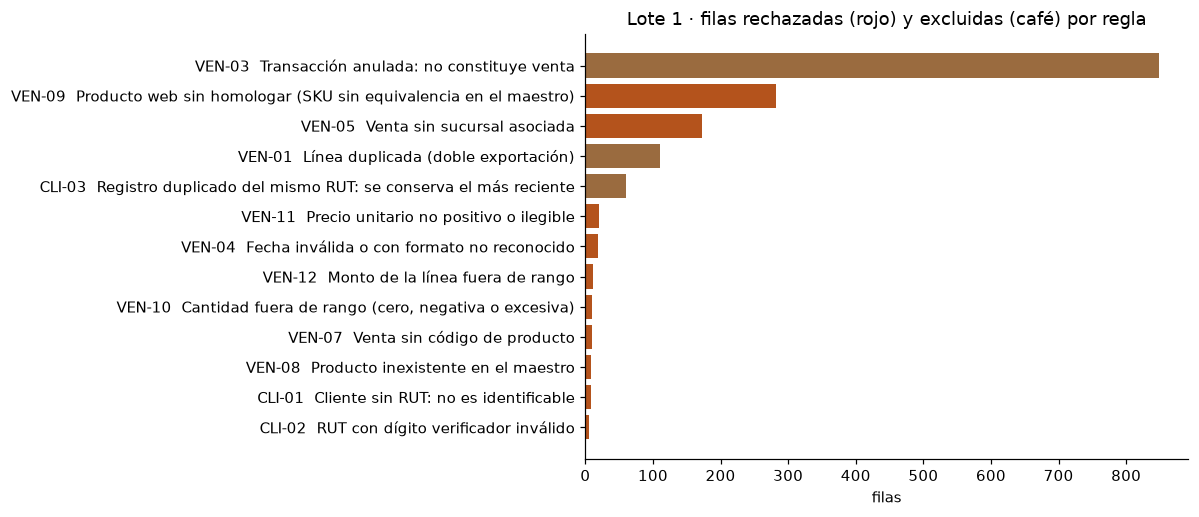

In [8]:
rechazos = consulta("""
    SELECT tipo, entidad, regla, motivo, COUNT(*) AS filas FROM etl_rechazos
    WHERE id_carga = :id GROUP BY tipo, entidad, regla, motivo ORDER BY tipo, regla""", id=r1["id_carga"])
display(rechazos)

datos = rechazos.sort_values("filas")
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.barh(datos["regla"] + "  " + datos["motivo"], datos["filas"],
        color=["#9a6b3f" if t == "EXCLUSION" else "#b4531c" for t in datos["tipo"]])
ax.set_title("Lote 1 · filas rechazadas (rojo) y excluidas (café) por regla")
ax.set_xlabel("filas")
plt.tight_layout()
plt.show()

In [9]:
ejemplo = consulta("""SELECT regla, motivo, archivo_origen, fila_origen, registro FROM etl_rechazos
                       WHERE id_carga = :id AND regla = 'VEN-05' LIMIT 1""", id=r1["id_carga"]).iloc[0]
print({k: ejemplo[k] for k in ("regla", "motivo", "archivo_origen", "fila_origen")})
print("Registro original guardado en la tabla de rechazos (datos personales enmascarados):")
print(json.dumps(json.loads(ejemplo["registro"]), ensure_ascii=False, indent=1))

{'regla': 'VEN-05', 'motivo': 'Venta sin sucursal asociada', 'archivo_origen': 'pos_ventas_tiendas.csv', 'fila_origen': np.int64(470)}
Registro original guardado en la tabla de rechazos (datos personales enmascarados):
{
 "nro_boleta": "B10-0000271",
 "linea": "1",
 "fecha_hora": "09/01/2025 17:14",
 "cod_sucursal": "",
 "rut_cliente": "",
 "cod_producto": "P0097",
 "cantidad": "1",
 "precio_unitario": "5990",
 "descuento": "0",
 "estado": "COMPLETADA"
}


In [10]:
silver_ventas = pd.read_parquet(config.SILVER / "ventas")
casos = {
    "precio con formato moneda": bronze_pos["precio_unitario"].str.startswith("$"),
    "fecha aaaa-mm-dd": bronze_pos["fecha_hora"].str.match(r"^\d{4}-"),
    "fecha dd-mm-aaaa": bronze_pos["fecha_hora"].str.match(r"^\d{2}-"),
    "estado en minúsculas": bronze_pos["estado"].str.islower(),
    "estado con espacio final": bronze_pos["estado"].str.endswith(" "),
    "devolución": bronze_pos["estado"].str.strip().str.upper().eq("DEVUELTA"),
}
limpias = silver_ventas.assign(linea=silver_ventas["nro_linea"].astype(str))
filas = []
for problema, mascara in casos.items():
    cruce = bronze_pos[mascara].merge(limpias, left_on=["nro_boleta", "linea"], right_on=["numero_documento", "linea"],
                                      suffixes=("_bronze", "_silver")).head(1)
    filas.append(cruce.assign(problema=problema))
antes_despues = pd.concat(filas, ignore_index=True)
print("Antes (Bronze, texto crudo) y después (Silver, tipado y homologado):")
antes_despues[["problema", "nro_boleta", "fecha_hora_bronze", "fecha_hora_silver", "precio_unitario_bronze",
               "precio_unitario_silver", "estado", "es_devolucion"]].assign(estado=lambda d: "'" + d["estado"] + "'")

Antes (Bronze, texto crudo) y después (Silver, tipado y homologado):


,problema,nro_boleta,fecha_hora_bronze,fecha_hora_silver,precio_unitario_bronze,precio_unitario_silver,estado,es_devolucion
0,precio con formato moneda,B02-0000005,2025-01-01 13:31:00,2025-01-01 13:31:00,$1.012.990,1012990,'completada',0
1,fecha aaaa-mm-dd,B02-0000004,2025-01-01 11:05:00,2025-01-01 11:05:00,89990,89990,'COMPLETADA',0
2,fecha dd-mm-aaaa,B07-0000036,02-01-2025 15:10,2025-01-02 15:10:00,$32.990,32990,'COMPLETADA',0
3,estado en minúsculas,B02-0000005,2025-01-01 13:31:00,2025-01-01 13:31:00,$1.012.990,1012990,'completada',0
4,estado con espacio final,B04-0000012,2025-01-01 19:18:00,2025-01-01 19:18:00,1164990,1164990,'Completada ',0
5,devolución,B07-0000019,01/01/2025 15:33,2025-01-01 15:33:00,381990,381990,'DEVUELTA',1


In [11]:
base = config.SILVER / "ventas"
particiones = sorted(p.parent.relative_to(base).as_posix() for p in base.glob("anio=*/mes=*/*.parquet"))
print(f"Silver ventas particionado en {len(particiones)} carpetas:", particiones[:3], "...")

tamano_parquet = sum(p.stat().st_size for p in base.rglob("*.parquet"))
temporal = config.DATA / "_comparacion.csv"
silver_ventas.to_csv(temporal, index=False)
tamano_csv = temporal.stat().st_size
temporal.unlink()
print(f"Mismas {len(silver_ventas):,} filas -> CSV {tamano_csv / 1024:,.0f} KB vs Parquet {tamano_parquet / 1024:,.0f} KB "
      f"({tamano_csv / tamano_parquet:.1f}× más liviano)")

marzo = pd.read_parquet(base, filters=[("anio", "=", 2025), ("mes", "=", 3)])
print(f"Consulta de marzo 2025: lee solo 1 partición ({len(marzo):,} filas) en vez de las {len(silver_ventas):,}")

Silver ventas particionado en 12 carpetas: ['anio=2025/mes=01', 'anio=2025/mes=02', 'anio=2025/mes=03'] ...


Mismas 27,589 filas -> CSV 4,079 KB vs Parquet 948 KB (4.3× más liviano)
Consulta de marzo 2025: lee solo 1 partición (2,206 filas) en vez de las 27,589


## 5. Capa Gold — el esquema estrella

Modelo derivado de la Bus Matrix de la EP1: proceso **Ventas**, grano **una línea de producto de cada boleta o pedido**,
cinco dimensiones conformadas, con claves sustitutas (en fecha, AAAAMMDD). El diagrama se genera desde el esquema real de la base
(`python -m src.documentacion`) y también se exporta a `docs/modelo_estrella.drawio` para editarlo en Draw.io.

![Modelo estrella](../docs/modelo_estrella.png)

In [12]:
tablas = ["dim_fecha", "dim_canal", "dim_sucursal", "dim_producto", "dim_cliente", "fact_ventas",
          "etl_rechazos", "etl_validaciones", "etl_control_cargas", "agg_ventas_mes_region"]
pd.DataFrame({"tabla": tablas, "filas": [consulta(f"SELECT COUNT(*) AS n FROM {t}")["n"].iat[0] for t in tablas]})

,tabla,filas
0,dim_fecha,365
1,dim_canal,3
2,dim_sucursal,13
3,dim_producto,144
4,dim_cliente,1501
5,fact_ventas,27589
6,etl_rechazos,1565
7,etl_validaciones,9
8,etl_control_cargas,1
9,agg_ventas_mes_region,120


,fecha,canal,sucursal,region_sucursal,producto,categoria,segmento_cliente,unidades,monto_neto,venta_neta
0,2025-01-01,Tienda física,Santiago Centro,Metropolitana,Set de ollas Tramontina D80,Hogar,Ocasional,1,42990,42990
1,2025-01-01,Tienda física,Santiago Centro,Metropolitana,Cargador USB-C Xiaomi N41,Accesorios,VIP,1,5990,5990
2,2025-01-01,Tienda física,Providencia,Metropolitana,Bolso de viaje Samsonite T62,Accesorios,Frecuente,1,35990,35990
3,2025-01-01,Tienda física,Providencia,Metropolitana,Hervidor Samsung E44,Hogar,Frecuente,2,365980,365980
4,2025-01-01,Tienda física,Providencia,Metropolitana,Cable USB-C Xiaomi T89,Accesorios,Frecuente,1,15990,15990


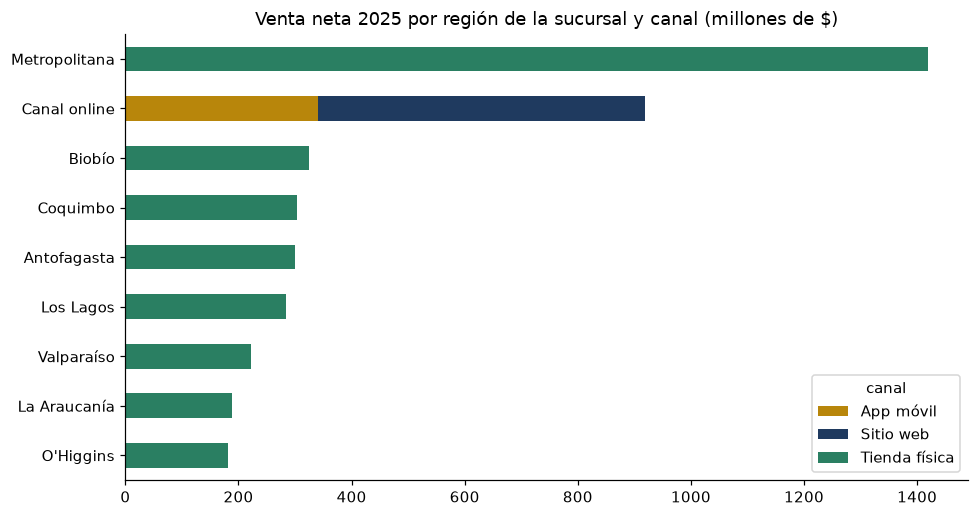

In [13]:
display(consulta("""SELECT fecha, canal, sucursal, region_sucursal, producto, categoria, segmento_cliente,
                            unidades, monto_neto, venta_neta FROM vw_ventas LIMIT 5"""))

por_region = consulta("""SELECT region_sucursal AS region, canal, SUM(venta_neta) AS venta_neta
                           FROM vw_ventas WHERE anio = 2025 GROUP BY region_sucursal, canal""")
tabla = por_region.pivot(index="region", columns="canal", values="venta_neta").fillna(0)
tabla = tabla.loc[tabla.sum(axis=1).sort_values().index] / 1e6
ax = tabla.plot.barh(stacked=True, figsize=(9, 4.8), color=["#b8860b", "#1f3a5f", "#2a7f62"])
ax.set_title("Venta neta 2025 por región de la sucursal y canal (millones de $)")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

## 6. Carga incremental — lote 2 (enero a junio 2026) y Slowly Changing Dimensions

El lote 2 trae ventas nuevas y también cambios en los maestros: clientes que se mudan o cambian de segmento,
productos reclasificados, precios y marcas corregidos, una sucursal nueva y una dirección corregida.
Cada tipo de cambio se gestiona con la técnica SCD que corresponde a lo que el negocio necesita recordar.

In [14]:
r2 = pipeline.ejecutar(2)
pd.DataFrame({"lote 1": r1, "lote 2": r2}).drop(index="id_carga")

2026-10-24 22:49:55 | INFO    | dr360 | ===== Inicio carga L2-20261024-224955-de28 (lote 2) =====


2026-10-24 22:49:55 | INFO    | dr360 | Bronze | pos_ventas             |  11046 filas | pos_ventas_tiendas.csv (sha256 c01e716aefa4)


2026-10-24 22:49:55 | INFO    | dr360 | Bronze | ecommerce_pedidos      |   2199 filas | ecommerce_pedidos.json (sha256 aede7e54c8b1)


2026-10-24 22:49:55 | INFO    | dr360 | Bronze | crm_clientes           |   1694 filas | crm_clientes.db (sha256 dc2b560626b1)


2026-10-24 22:49:55 | INFO    | dr360 | Bronze | maestro_productos      |    154 filas | maestro_productos.csv (sha256 0ab039e5e62d)


...

2026-10-24 22:49:55 | INFO    | dr360 | Valid. | OK    | V07 Regla de cálculo: monto_neto = monto_bruto - descuento | 0 filas con monto neto mal calculado


2026-10-24 22:49:55 | INFO    | dr360 | Valid. | OK    | V08 Sin líneas duplicadas en el hecho | 0 claves naturales repetidas


2026-10-24 22:49:55 | INFO    | dr360 | Valid. | OK    | V09 Gold sin datos personales directos | columnas personales en Gold: ninguna


2026-10-24 22:49:55 | INFO    | dr360 | ===== Fin carga L2-20261024-224955-de28: EXITOSA (13464 líneas nuevas en fact_ventas, 0 ya existían) =====


,lote 1,lote 2
lineas_leidas,29080,14091
lineas_validas,27589,13464
lineas_rechazadas,531,215
lineas_excluidas,960,412
clientes_leidos,1574,1694
clientes_validos,1500,1620
ventas_pos_rut_sin_match,0,0
ventas_web_sin_cliente,787,385
correos_invalidos_anulados,30,30
clientes_sin_comuna,30,30


### SCD tipo 2 — Cliente (comuna/región y segmento)

Cuando un cliente se muda o cambia de segmento se **cierra** su versión vigente y se **abre** una nueva con su propia
clave sustituta y su vigencia. Las ventas se enlazan a la versión vigente **en la fecha de la venta**,
así las ventas de 2025 conservan la región que el cliente tenía en ese momento.

In [15]:
caso = consulta("""
    SELECT cl.id_cliente FROM dim_cliente cl JOIN fact_ventas f ON f.sk_cliente = cl.sk_cliente
    WHERE cl.id_cliente IN (SELECT id_cliente FROM dim_cliente WHERE version = 2)
    GROUP BY cl.id_cliente
    HAVING COUNT(DISTINCT cl.sk_cliente) = 2 AND COUNT(DISTINCT cl.region) = 2
    ORDER BY cl.id_cliente LIMIT 1""")["id_cliente"].iat[0]
print("Versiones del cliente", caso, "(id seudonimizado):")
display(consulta("""SELECT sk_cliente, version, comuna, region, segmento, fecha_inicio_vigencia,
                            fecha_fin_vigencia, es_actual FROM dim_cliente WHERE id_cliente = :id ORDER BY version""", id=caso))
print("Sus compras y la versión a la que quedó enlazada cada una:")
consulta("""SELECT d.fecha, f.numero_documento, f.sk_cliente, cl.version, cl.region AS region_al_comprar, f.monto_neto
            FROM fact_ventas f JOIN dim_cliente cl ON cl.sk_cliente = f.sk_cliente
            JOIN dim_fecha d ON d.sk_fecha = f.sk_fecha WHERE cl.id_cliente = :id ORDER BY d.fecha""", id=caso)

Versiones del cliente 032da87e93c64df9 (id seudonimizado):


,sk_cliente,version,comuna,region,segmento,fecha_inicio_vigencia,fecha_fin_vigencia,es_actual
0,1280,1,Valparaíso,Valparaíso,Ocasional,1900-01-01,2026-03-24,0
1,1736,2,Ñuñoa,Metropolitana,Ocasional,2026-03-25,9999-12-31,1


Sus compras y la versión a la que quedó enlazada cada una:


,fecha,numero_documento,sk_cliente,version,region_al_comprar,monto_neto
0,2025-01-17,WEB-0000214,1280,1,Valparaíso,29690
1,2025-03-05,WEB-0000797,1280,1,Valparaíso,5990
2,2025-03-05,WEB-0000797,1280,1,Valparaíso,373490
3,2025-03-05,WEB-0000797,1280,1,Valparaíso,8990
4,2025-03-17,B05-0002577,1280,1,Valparaíso,170990
5,2025-03-17,B05-0002577,1280,1,Valparaíso,284990
6,2025-03-17,B05-0002577,1280,1,Valparaíso,92990
7,2025-03-17,B05-0002577,1280,1,Valparaíso,413980
8,2025-03-17,WEB-0000929,1280,1,Valparaíso,92990
9,2025-09-02,B07-0008497,1280,1,Valparaíso,6990


In [16]:
display(consulta("""SELECT version, COUNT(*) AS clientes FROM dim_cliente WHERE sk_cliente <> -1
                       GROUP BY version""").rename(columns={"version": "versiones del cliente"}))
impacto = consulta("""
    SELECT COUNT(*) AS ventas, SUM(f.monto_neto) AS monto
    FROM fact_ventas f
    JOIN dim_cliente cl     ON cl.sk_cliente = f.sk_cliente
    JOIN dim_cliente actual ON actual.id_cliente = cl.id_cliente AND actual.es_actual = 1
    WHERE cl.es_actual = 0 AND cl.region <> actual.region""").iloc[0]
print(f"{int(impacto.ventas):,} ventas por {clp(impacto.monto)} conservan la región del cliente al momento de comprar. "
      "Con SCD tipo 1 (sobrescribir) se habrían reasignado a su región actual y el análisis histórico quedaría mal.")

,versiones del cliente,clientes
0,1,1620
1,2,136


1,386 ventas por $187.664.580 conservan la región del cliente al momento de comprar. Con SCD tipo 1 (sobrescribir) se habrían reasignado a su región actual y el análisis histórico quedaría mal.


### SCD tipo 3 — Categoría del producto

En 2026 la línea **Smartwatches** pasa de *Accesorios* a *Tecnología*. Con SCD tipo 3 se guarda la categoría
vigente y la anterior en columnas separadas: así se puede reportar con cualquiera de las dos clasificaciones
y comparar *antes y después* de la reclasificación.

In [17]:
display(consulta("""SELECT cod_producto, nombre_producto, subcategoria, categoria_anterior, categoria,
                            fecha_cambio_categoria FROM dim_producto WHERE categoria_anterior IS NOT NULL LIMIT 5"""))
consulta("""SELECT anio,
                   SUM(CASE WHEN categoria = 'Tecnología' THEN venta_neta END) AS tecnologia_clasificacion_vigente,
                   SUM(CASE WHEN COALESCE(categoria_anterior, categoria) = 'Tecnología' THEN venta_neta END)
                       AS tecnologia_clasificacion_anterior
            FROM vw_ventas GROUP BY anio""")

,cod_producto,nombre_producto,subcategoria,categoria_anterior,categoria,fecha_cambio_categoria
0,P0133,Smartwatch Apple W21,Smartwatches,Accesorios,Tecnología,2026-10-24
1,P0134,Pulsera De Actividad Samsung G34,Smartwatches,Accesorios,Tecnología,2026-10-24
2,P0135,Smartwatch Xiaomi Y55,Smartwatches,Accesorios,Tecnología,2026-10-24
3,P0136,Pulsera de actividad Huawei S22,Smartwatches,Accesorios,Tecnología,2026-10-24
4,P0137,Smartwatch Apple T55,Smartwatches,Accesorios,Tecnología,2026-10-24


,anio,tecnologia_clasificacion_vigente,tecnologia_clasificacion_anterior
0,2025,2775928020,2404643680
1,2026,1439459680,1286765980


### SCD tipo 1 — Correcciones sin historia

Los errores corregidos (marca mal escrita, dirección equivocada) y los atributos cuya historia no interesa
(precio de lista vigente) se **sobrescriben**. Gold no guarda el valor anterior, pero **Bronze sí**:
la trazabilidad no se pierde.

In [18]:
display(consulta("""SELECT cod_sucursal, nombre_sucursal, direccion, fecha_actualizacion, id_carga
                       FROM dim_sucursal WHERE cod_sucursal IN ('SUC-04', 'SUC-13')"""))

lote1 = pd.read_parquet(config.BRONZE / "maestro_productos" / "lote=1" / "datos.parquet")[["cod_producto", "marca", "precio_lista"]]
actual = consulta("SELECT cod_producto, nombre_producto, marca, precio_lista FROM dim_producto")
comparacion = lote1.merge(actual, on="cod_producto", suffixes=("_bronze_lote1", "_gold"))
comparacion["precio_lista_bronze_lote1"] = comparacion["precio_lista_bronze_lote1"].astype(int)
cambiados = comparacion[(comparacion["marca_bronze_lote1"] != comparacion["marca_gold"])
                        | (comparacion["precio_lista_bronze_lote1"] != comparacion["precio_lista_gold"])]
print(f"{len(cambiados)} productos con marca o precio corregidos (SCD tipo 1). Ejemplos:")
cambiados.head(8)

,cod_sucursal,nombre_sucursal,direccion,fecha_actualizacion,id_carga
0,SUC-04,Maipú,"Av. Américo Vespucio 1001, local 112",2026-10-24,L2-20261024-224955-de28
1,SUC-13,Iquique,Av. Héroes de la Concepción 2555,2026-10-24,L2-20261024-224955-de28


25 productos con marca o precio corregidos (SCD tipo 1). Ejemplos:


,cod_producto,marca_bronze_lote1,precio_lista_bronze_lote1,nombre_producto,marca_gold,precio_lista_gold
5,P0006,Xiaomi,672990,Smartphone Xiaomi H35,Xiaomi,726990
9,P0010,Xiaomi,1166990,Smartphone Xiaomi P96,Xiaomi,1260990
11,P0012,Motorola,1214990,Smartphone Motorola P93,Motorola,1312990
15,P0016,Apple,1012990,Notebook Apple C45,Apple,1094990
18,P0019,Asus,1284990,Notebook Asus W56,Asus,1387990
39,P0040,Bose,142990,Audífonos inalámbricos Bose U96,Bose,154990
46,P0047,Xiaomy,304990,Parlante Bluetooth Xiaomi R32,Xiaomi,304990
49,P0050,Thomas,54990,Freidora de aire Thomas P96,Thomas,59990


## 7. Idempotencia — volver a ejecutar no duplica

Se ejecuta otra vez el lote 2. La clave natural `(fuente_origen, numero_documento, nro_linea)` impide insertar
dos veces la misma línea y las dimensiones solo cambian si llega un cambio real.

In [19]:
antes = consulta("SELECT COUNT(*) AS filas, SUM(monto_neto) AS monto_neto FROM fact_ventas").iloc[0]
r3 = pipeline.ejecutar(2)
despues = consulta("SELECT COUNT(*) AS filas, SUM(monto_neto) AS monto_neto FROM fact_ventas").iloc[0]
print(f"Re-ejecución: {r3['fact_insertadas']} líneas insertadas, {r3['fact_omitidas']:,} ya existían; "
      f"nuevas versiones SCD2: {r3['clientes_scd2_nuevas_versiones']}")
pd.DataFrame({"antes": antes, "después": despues})

2026-10-24 22:49:55 | INFO    | dr360 | ===== Inicio carga L2-20261024-224955-af0a (lote 2) =====


2026-10-24 22:49:55 | INFO    | dr360 | Bronze | pos_ventas             |  11046 filas | pos_ventas_tiendas.csv (sha256 c01e716aefa4)


2026-10-24 22:49:56 | INFO    | dr360 | Bronze | ecommerce_pedidos      |   2199 filas | ecommerce_pedidos.json (sha256 aede7e54c8b1)


2026-10-24 22:49:56 | INFO    | dr360 | Bronze | crm_clientes           |   1694 filas | crm_clientes.db (sha256 dc2b560626b1)


2026-10-24 22:49:56 | INFO    | dr360 | Bronze | maestro_productos      |    154 filas | maestro_productos.csv (sha256 0ab039e5e62d)


...

2026-10-24 22:49:56 | INFO    | dr360 | Valid. | OK    | V08 Sin líneas duplicadas en el hecho | 0 claves naturales repetidas


2026-10-24 22:49:56 | INFO    | dr360 | Valid. | OK    | V09 Gold sin datos personales directos | columnas personales en Gold: ninguna


2026-10-24 22:49:56 | INFO    | dr360 | ===== Fin carga L2-20261024-224955-af0a: EXITOSA (0 líneas nuevas en fact_ventas, 13464 ya existían) =====


Re-ejecución: 0 líneas insertadas, 13,464 ya existían; nuevas versiones SCD2: 0


,antes,después
filas,41053,41053
monto_neto,6449770640,6449770640


## 8. Manejo de errores — una fuente que rompe el contrato

Se simula un lote 3 cuyo archivo POS llega **sin la columna `estado`**. El contrato de datos lo detecta en Bronze,
el pipeline **falla de forma visible** (log ERROR), la carga queda registrada como `FALLIDA` en `etl_control_cargas`
y Gold no se modifica.

In [20]:
lote_roto = config.FUENTES / "lote_3"
shutil.copytree(config.FUENTES / "lote_2", lote_roto, dirs_exist_ok=True)
pos_roto = pd.read_csv(lote_roto / "pos_ventas_tiendas.csv", sep=";", dtype=str).drop(columns=["estado"])
pos_roto.to_csv(lote_roto / "pos_ventas_tiendas.csv", sep=";", index=False)

filas_antes = consulta("SELECT COUNT(*) AS n FROM fact_ventas")["n"].iat[0]
try:
    pipeline.ejecutar(3)
except bronze.ContratoError as exc:
    print("Error capturado por el orquestador:", exc)
finally:
    shutil.rmtree(lote_roto)
print("Filas en fact_ventas antes / después del intento:", filas_antes, "/",
      consulta("SELECT COUNT(*) AS n FROM fact_ventas")["n"].iat[0])
consulta("""SELECT id_carga, lote, estado, lineas_leidas, lineas_rechazadas, lineas_excluidas,
                   filas_insertadas_fact, filas_omitidas_ya_cargadas, version_codigo, mensaje
            FROM etl_control_cargas ORDER BY inicio""").convert_dtypes()

2026-10-24 22:49:56 | INFO    | dr360 | ===== Inicio carga L3-20261024-224956-409c (lote 3) =====


2026-10-24 22:49:56 | ERROR   | dr360 | Carga L3-20261024-224956-409c FALLIDA: La fuente pos_ventas no trae las columnas ['estado']


Error capturado por el orquestador: La fuente pos_ventas no trae las columnas ['estado']
Filas en fact_ventas antes / después del intento: 41053 / 41053


,id_carga,lote,estado,lineas_leidas,lineas_rechazadas,lineas_excluidas,filas_insertadas_fact,filas_omitidas_ya_cargadas,version_codigo,mensaje
0,L1-20261024-224954-2c3e,1,EXITOSA,29080,531,960,27589,0,ef6056d+cambios-sin-commit,<NA>
1,L2-20261024-224955-de28,2,EXITOSA,14091,215,412,13464,0,ef6056d+cambios-sin-commit,<NA>
2,L2-20261024-224955-af0a,2,EXITOSA,14091,215,412,0,13464,ef6056d+cambios-sin-commit,<NA>
3,L3-20261024-224956-409c,3,FALLIDA,<NA>,<NA>,<NA>,<NA>,<NA>,ef6056d+cambios-sin-commit,ContratoError: La fuente pos_ventas no trae la...


## 9. Validaciones de cierre y trazabilidad extremo a extremo

Las 9 validaciones corren antes de confirmar cada carga y quedan registradas en `etl_validaciones`.
Después se sigue **una cifra del hecho hasta la línea exacta del archivo fuente** (Gold → Bronze → archivo).

In [21]:
consulta("SELECT validacion, resultado, detalle FROM etl_validaciones WHERE id_carga = :id", id=r2["id_carga"])

,validacion,resultado,detalle
0,V01 Conservación de filas Bronze -> Silver,OK,14091 leídas = 13464 válidas + 215 rechazadas ...
1,V02 Integridad referencial del hecho,OK,0 filas huérfanas
2,V03 SCD2: exactamente una versión vigente por ...,OK,0 clientes con 0 o más de 1 versión vigente
3,V04 SCD2: vigencias sin traslape,OK,0 pares de versiones traslapadas
4,V05 SCD2: cada venta apunta a la versión vigen...,OK,0 ventas asignadas a una versión no vigente
5,V06 Cuadratura Silver -> Gold (filas y monto n...,OK,"Silver 13464 filas / $2,182,632,080 vs Gold 13..."
6,V07 Regla de cálculo: monto_neto = monto_bruto...,OK,0 filas con monto neto mal calculado
7,V08 Sin líneas duplicadas en el hecho,OK,0 claves naturales repetidas
8,V09 Gold sin datos personales directos,OK,columnas personales en Gold: ninguna


In [22]:
fila = consulta("""
    SELECT f.sk_venta, d.fecha, p.nombre_producto, s.nombre_sucursal, f.cantidad, f.precio_unitario, f.descuento,
           f.monto_neto, f.id_carga, f.archivo_origen, f.fila_origen, c.lote
    FROM fact_ventas f
    JOIN dim_fecha d    ON d.sk_fecha = f.sk_fecha
    JOIN dim_producto p ON p.sk_producto = f.sk_producto
    JOIN dim_sucursal s ON s.sk_sucursal = f.sk_sucursal
    JOIN etl_control_cargas c ON c.id_carga = f.id_carga
    WHERE f.fuente_origen = 'POS' AND f.descuento > 0 ORDER BY f.sk_venta LIMIT 1""").iloc[0]
print("1) Gold · fact_ventas")
display(fila.to_frame().T)

registro = pd.read_parquet(config.BRONZE / "pos_ventas" / f"lote={fila.lote}" / "datos.parquet")
registro = registro[registro["_fila_origen"] == str(fila.fila_origen)].assign(
    rut_cliente=lambda d: d["rut_cliente"].map(rc.enmascarar))
print("2) Bronze · registro crudo con sus metadatos de linaje")
display(registro)

linea = linecache.getline(str(config.FUENTES / f"lote_{fila.lote}" / fila.archivo_origen), int(fila.fila_origen)).strip()
campos = linea.split(";")
campos[4] = rc.enmascarar(campos[4])
print(f"3) Archivo fuente {fila.archivo_origen}, línea {fila.fila_origen}:")
print("   ", ";".join(campos))

1) Gold · fact_ventas


,sk_venta,fecha,nombre_producto,nombre_sucursal,cantidad,precio_unitario,descuento,monto_neto,id_carga,archivo_origen,fila_origen,lote
0,13,2025-01-01,Mochila para notebook Samsonite F41,Maipú,1,32990,1650,31340,L1-20261024-224954-2c3e,pos_ventas_tiendas.csv,14,1


2) Bronze · registro crudo con sus metadatos de linaje


,nro_boleta,linea,fecha_hora,cod_sucursal,rut_cliente,cod_producto,cantidad,precio_unitario,descuento,estado,_id_carga,_lote,_fuente,_archivo,_fila_origen,_hash_archivo,_fecha_ingesta
12,B04-0000011,1,01/01/2025 15:21,SUC-04,*******4-K,P0121,1,32990,1650,COMPLETADA,L1-20261024-224954-2c3e,1,pos_ventas,pos_ventas_tiendas.csv,14,2acd4716a9b3,2026-10-24T22:49:54


3) Archivo fuente pos_ventas_tiendas.csv, línea 14:
    B04-0000011;1;01/01/2025 15:21;SUC-04;*******4-K;P0121;1;32990;1650;COMPLETADA


## 10. Optimización y capa semántica para IA

* **Índices** en las claves foráneas del hecho: el motor busca por índice en vez de recorrer la tabla.
* **Agregado precalculado** `agg_ventas_mes_region` (emula una vista materializada; se refresca en cada carga).
* **Capa semántica** (`docs/capa_semantica.json`): nombres, sinónimos, métricas oficiales y reglas para que un
  asistente NLQ/text-to-SQL genere SQL correcto, siempre con **validación humana**.

In [23]:
for sql in ["SELECT SUM(monto_neto) FROM fact_ventas WHERE sk_producto = 25",
            "SELECT SUM(monto_neto) FROM fact_ventas WHERE sk_fecha BETWEEN 20260301 AND 20260331"]:
    print(sql, "\n   plan ->", consulta("EXPLAIN QUERY PLAN " + sql)["detail"].tolist())


def medir(sql: str, repeticiones: int = 10) -> float:
    engine = gold.motor()
    with engine.connect() as con:
        inicio = time.perf_counter()
        for _ in range(repeticiones):
            con.execute(text(sql)).fetchall()
        duracion = (time.perf_counter() - inicio) / repeticiones * 1000
    engine.dispose()
    return duracion


t_vista = medir("SELECT anio_mes, region_sucursal, canal, SUM(venta_neta) FROM vw_ventas GROUP BY 1, 2, 3")
t_agregado = medir("SELECT anio_mes, region, canal, venta_neta FROM agg_ventas_mes_region")
print(f"\nKPI venta neta por mes, región y canal: vista detalle {t_vista:.1f} ms vs agregado precalculado "
      f"{t_agregado:.2f} ms (≈{t_vista / t_agregado:.0f}× más rápido)")

SELECT SUM(monto_neto) FROM fact_ventas WHERE sk_producto = 25 
   plan -> ['SEARCH fact_ventas USING INDEX ix_fact_ventas_producto (sk_producto=?)']
SELECT SUM(monto_neto) FROM fact_ventas WHERE sk_fecha BETWEEN 20260301 AND 20260331 
   plan -> ['SEARCH fact_ventas USING INDEX ix_fact_ventas_fecha (sk_fecha>? AND sk_fecha<?)']



KPI venta neta por mes, región y canal: vista detalle 21.5 ms vs agregado precalculado 0.10 ms (≈219× más rápido)


In [24]:
semantica = json.loads((config.DOCS / "capa_semantica.json").read_text(encoding="utf-8"))
print("Métricas oficiales:", ", ".join(semantica["metricas"]))
for ejemplo in semantica["ejemplos_nlq"]:
    print("\nPregunta:", ejemplo["pregunta"])
    print("SQL generado desde la capa semántica:", ejemplo["sql"])
    display(consulta(ejemplo["sql"]))

resultado = consulta(semantica["ejemplos_nlq"][0]["sql"]).iat[0, 0]
oficial = consulta("SELECT venta_neta FROM vw_kpi_mensual WHERE canal = 'App móvil' AND anio_mes = '2026-03'").iat[0, 0]
print(f"\nChecklist de validación humana · contrastar con una cifra conocida: respuesta {clp(resultado)} "
      f"vs KPI oficial {clp(oficial)} -> {'coincide, se puede comunicar' if resultado == oficial else 'NO coincide: no comunicar'}")

Métricas oficiales: venta_neta, monto_devuelto, tasa_devolucion, unidades_vendidas, documentos, ticket_promedio, clientes_activos

Pregunta: ¿Cuál fue la venta neta de la app en marzo de 2026?
SQL generado desde la capa semántica: SELECT SUM(venta_neta) AS venta_neta FROM vw_ventas WHERE canal = 'App móvil' AND anio_mes = '2026-03'


,venta_neta
0,45388610



Pregunta: ¿Qué región tuvo el mayor ticket promedio en tiendas físicas durante 2025?
SQL generado desde la capa semántica: SELECT region_sucursal, SUM(venta_neta) * 1.0 / NULLIF(COUNT(DISTINCT CASE WHEN es_devolucion = 0 THEN numero_documento END), 0) AS ticket_promedio FROM vw_ventas WHERE canal = 'Tienda física' AND anio = 2025 GROUP BY region_sucursal ORDER BY ticket_promedio DESC LIMIT 1


,region_sucursal,ticket_promedio
0,Valparaíso,274396.194581



Pregunta: ¿Cuántos clientes VIP compraron en el primer semestre de 2026?
SQL generado desde la capa semántica: SELECT COUNT(DISTINCT id_cliente) FROM vw_ventas WHERE segmento_cliente = 'VIP' AND anio = 2026 AND semestre = 1 AND es_cliente_anonimo = 0 AND es_devolucion = 0


,COUNT(DISTINCT id_cliente)
0,180



Checklist de validación humana · contrastar con una cifra conocida: respuesta $45.388.610 vs KPI oficial $45.388.610 -> coincide, se puede comunicar


## 11. Primeras respuestas a las preguntas de negocio

Con Gold cargado ya podemos responder las preguntas descriptivas que planteamos en la EP1. Los dashboards de la etapa de visualización
se construirán sobre estas mismas vistas.

**¿Qué sucursales, canales o categorías explican mejor o peor desempeño de ventas?**

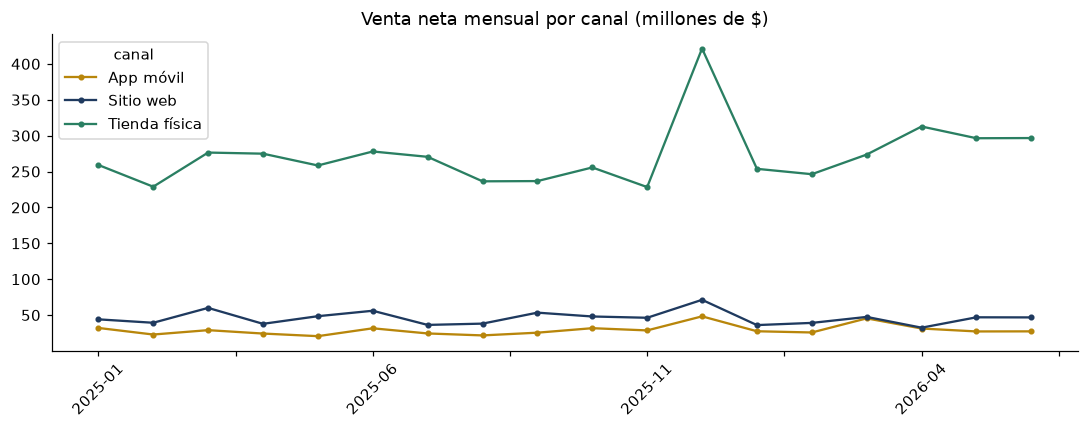

,canal,anio,venta_neta,ticket_promedio
0,App móvil,2025,340195640,212755.0
1,App móvil,2026,184239140,232919.0
2,Sitio web,2025,578592450,209029.0
3,Sitio web,2026,248522070,201396.0
4,Tienda física,2025,3224576090,259544.0
5,Tienda física,2026,1679450980,272020.0


,sucursal,region_sucursal,venta_neta_2025
0,Maipú,Metropolitana,333066290
1,Concepción,Biobío,324390650
10,Temuco,La Araucanía,188403380
11,Rancagua,O'Higgins,182089730


,categoria,subcategoria,venta_neta,pct_devolucion
0,Tecnología,Notebooks,1230996910,3.5
1,Tecnología,Smartphones,984447200,2.6
2,Tecnología,Televisores,975833620,3.5
3,Tecnología,Smartwatches,532536940,2.7
4,Tecnología,Audio,491573030,3.3
5,Hogar,Electrodomésticos,490836850,2.7
6,Hogar,Muebles,392372060,2.9
7,Accesorios,Mochilas,301645770,3.0


In [25]:
kpi = consulta("SELECT * FROM vw_kpi_mensual")
mensual = kpi.pivot(index="anio_mes", columns="canal", values="venta_neta") / 1e6
ax = mensual.plot(figsize=(10, 4), marker="o", ms=3, color=["#b8860b", "#1f3a5f", "#2a7f62"])
ax.set_title("Venta neta mensual por canal (millones de $)")
ax.set_xlabel("")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(consulta("""SELECT canal, anio, SUM(venta_neta) AS venta_neta,
                           ROUND(SUM(venta_neta) * 1.0 / COUNT(DISTINCT CASE WHEN es_devolucion = 0 THEN numero_documento END)) AS ticket_promedio
                    FROM vw_ventas GROUP BY canal, anio ORDER BY canal, anio"""))
display(consulta("""SELECT sucursal, region_sucursal, SUM(venta_neta) AS venta_neta_2025 FROM vw_ventas
                    WHERE anio = 2025 AND canal = 'Tienda física' GROUP BY sucursal, region_sucursal
                    ORDER BY venta_neta_2025 DESC""").iloc[[0, 1, -2, -1]])
consulta("""SELECT categoria, subcategoria, SUM(venta_neta) AS venta_neta,
                   ROUND(SUM(monto_devuelto) * 100.0 / NULLIF(SUM(venta_neta) + SUM(monto_devuelto), 0), 1) AS pct_devolucion
            FROM vw_ventas GROUP BY categoria, subcategoria ORDER BY venta_neta DESC LIMIT 8""")

**¿Cómo se comportan los clientes según recurrencia, canal o segmento?**

In [26]:
recurrencia = consulta("""
    SELECT CASE WHEN compras = 1 THEN '1 compra' WHEN compras <= 3 THEN '2 a 3 compras'
                WHEN compras <= 6 THEN '4 a 6 compras' ELSE '7 o más' END AS recurrencia_2025,
           COUNT(*) AS clientes, ROUND(AVG(venta)) AS venta_promedio_por_cliente
    FROM (SELECT id_cliente, COUNT(DISTINCT numero_documento) AS compras, SUM(venta_neta) AS venta
          FROM vw_ventas WHERE anio = 2025 AND es_cliente_anonimo = 0 AND es_devolucion = 0 GROUP BY id_cliente)
    GROUP BY 1 ORDER BY MIN(compras)""")
display(recurrencia)
consulta("""SELECT segmento_cliente, canal, COUNT(DISTINCT id_cliente) AS clientes, SUM(venta_neta) AS venta_neta
            FROM vw_ventas WHERE es_cliente_anonimo = 0 AND anio = 2025
            GROUP BY segmento_cliente, canal ORDER BY segmento_cliente, venta_neta DESC""")

,recurrencia_2025,clientes,venta_promedio_por_cliente
0,1 compra,5,241256.0
1,2 a 3 compras,59,591052.0
2,4 a 6 compras,423,1323906.0
3,7 o más,1012,2260614.0


,segmento_cliente,canal,clientes,venta_neta
0,Frecuente,Tienda física,486,654635980
1,Frecuente,Sitio web,394,162968760
2,Frecuente,App móvil,294,87947960
3,Nuevo,Tienda física,247,370803750
4,Nuevo,Sitio web,194,72594540
5,Nuevo,App móvil,162,58462870
6,Ocasional,Tienda física,605,830699230
7,Ocasional,Sitio web,500,210283610
8,Ocasional,App móvil,362,115011800
9,VIP,Tienda física,154,227735170


**¿Qué indicadores deben seguir las áreas, y cómo aseguramos que sean confiables y consistentes?**
Las métricas oficiales viven en `docs/capa_semantica.json` y en las vistas: una sola definición de venta neta,
monto devuelto, tasa de devolución, unidades vendidas, documentos, ticket promedio y clientes activos. Su confiabilidad
la sostienen las 9 validaciones de cierre, la tabla de rechazos y el linaje de cada fila. Para la IA generativa, la capa
semántica fija qué vistas consultar y cómo, y toda respuesta pasa por el checklist de validación humana (sección 10).

## 12. Control de versiones

Cada carga registra el commit de Git con el que se ejecutó (`version_codigo`), lo que une la trazabilidad
del dato con la trazabilidad del código.

In [27]:
historial = subprocess.run(["git", "log", "--oneline", "-n", "15"], cwd=RAIZ, capture_output=True, text=True)
print(historial.stdout or "El repositorio aún no tiene commits.")
consulta("SELECT id_carga, estado, version_codigo FROM etl_control_cargas ORDER BY inicio")

ef6056d Merge pull request #1 from catluvies/gold-scd
f0d38c1 docs(notebook): agrega notebook de evidencias
f60c491 docs: agrega capa semántica y diagramas
de884dc feat(pipeline): agrega orquestador y validaciones de cierre
a1fef4c feat(gold): agrega dimensiones SCD y carga idempotente del hecho
2ea8a1a feat(sql): agrega esquema estrella y vistas semánticas
085fc5f Capa Silver: limpieza, deduplicación, homologación y tabla de rechazos
509e05e Capa Bronze: ingesta cruda con contrato de columnas y linaje
a3ff758 Generador de fuentes simuladas del caso (lotes 1 y 2)
7c5de42 Reglas de calidad de datos
fbc4ed9 Estructura base del proyecto y configuración



,id_carga,estado,version_codigo
0,L1-20261024-224954-2c3e,EXITOSA,ef6056d+cambios-sin-commit
1,L2-20261024-224955-de28,EXITOSA,ef6056d+cambios-sin-commit
2,L2-20261024-224955-af0a,EXITOSA,ef6056d+cambios-sin-commit
3,L3-20261024-224956-409c,FALLIDA,ef6056d+cambios-sin-commit


## Conclusión

El pipeline transforma siete fuentes heterogéneas y con fallas de calidad en un esquema estrella confiable:
cada línea leída queda contabilizada (válida, rechazada o excluida), las dimensiones gestionan su evolución con
SCD 1, 2 y 3, la carga es idempotente y transaccional, y cada venta de Gold puede rastrearse hasta la línea
exacta de su archivo fuente. Gold queda listo para el modelo semántico y los dashboards de la etapa de visualización.